# ⚽📈 A Evolução Ofensiva e Consistência das Equipes ⚽📈

## 1. Contexto e Objetivo
O futebol brasileiro é frequentemente rotulado como muito tático e defensivo. Mas será que a média de gols por partida vem caindo ou subindo ao longo dos anos? Além disso, olhando para a tabela, quais são as equipes mais sólidas do país e quais vivem em uma eterna montanha-russa (times "ioiô")?

**Objetivos da Análise:**
1. Analisar a evolução da média e distribuição de gols por partida ao longo das temporadas.
2. Calcular o desvio padrão das posições finais das equipes para identificar os times mais consistentes e os mais instáveis da era dos pontos corridos.

**Fontes de Dados (Kaggle):**
* [Histórico do Campeonato Brasileiro (2003-2024)](https://www.kaggle.com/datasets/lucasyukioimafuko/brasileirao-serie-a-2006-2022)
* [Histórico de Partidas e média de público.](https://www.kaggle.com/datasets/rczekster/matches-brazilian-football-from-2003-to-2019)

## 2. Preparação dos Dados
Nesta etapa, vamos carregar os dados de partidas (`df_partidas`) para a análise de gols, e os dados de classificação final (`df_brasileirao`) para a análise de consistência das equipes.

In [ ]:
from google.colab import auth

try:
    auth.authenticate_user()
    print("Usuário autenticado com sucesso no Google Cloud!")
except Exception as e:
    print(f"[Erro de Autenticação]: {e}")

Usuário autenticado com sucesso no Google Cloud!


In [ ]:
from google.cloud import bigquery
import sys

client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_brazilian_league`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_brasileirao = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
client = bigquery.Client(project='data-science-brasileirao')
query = """
    SELECT * FROM `data-science-brasileirao.brasileirao_dataset.dados_matches`
"""

try:
    print("Iniciando a extração dos dados do Campeonato Brasileiro...")
    df_partidas = client.query(query).to_dataframe()
    print("Os dados foram carregados com sucesso para o ambiente Python!")
except Exception as e:
    print(f"[Erro na conexão com o BigQuery]: {e}", file=sys.stderr)

Iniciando a extração dos dados do Campeonato Brasileiro...
Os dados foram carregados com sucesso para o ambiente Python!


In [ ]:
df_partidas = pd.DataFrame(df_partidas)

df_partidas [['home_team_score', 'away_team_score']] = df_partidas['score'].str.split('x', expand=True)
df_partidas

,date,hour,home_team,score,away_team,home_team_score,away_team_score
0,07/10/2022,00:00,América Mineiro,1x2,São Paulo,1,2
1,22/07/2022,00:00,América Mineiro,0x1,Palmeiras,0,1
2,16/10/2022,00:30,América Mineiro,1x2,Fortaleza,1,2
3,04/09/2022,00:30,América Mineiro,2x0,Coritiba,2,0
4,22/05/2022,01:00,América Mineiro,1x1,Botafogo,1,1
...,...,...,...,...,...,...,...
9161,31/08/2025,22:30,Vitória,1x0,Atlético Mineiro,1,0
9162,25/05/2025,22:30,Vitória,0x1,Santos,0,1
9163,12/06/2025,23:00,Vitória,0x0,Cruzeiro,0,0
9164,02/10/2025,23:00,Vitória,1x0,Ceará,1,0


In [ ]:
colunas_placar = ['home_team_score', 'away_team_score']
df_partidas[colunas_placar] = df_partidas[colunas_placar].apply(pd.to_numeric, errors='coerce').astype(int)

In [ ]:
df_partidas['date'] = pd.to_datetime(df_partidas['date'], format='%d/%m/%Y')
df_partidas

,date,hour,home_team,score,away_team,home_team_score,away_team_score
0,2022-10-07,00:00,América Mineiro,1x2,São Paulo,1,2
1,2022-07-22,00:00,América Mineiro,0x1,Palmeiras,0,1
2,2022-10-16,00:30,América Mineiro,1x2,Fortaleza,1,2
3,2022-09-04,00:30,América Mineiro,2x0,Coritiba,2,0
4,2022-05-22,01:00,América Mineiro,1x1,Botafogo,1,1
...,...,...,...,...,...,...,...
9161,2025-08-31,22:30,Vitória,1x0,Atlético Mineiro,1,0
9162,2025-05-25,22:30,Vitória,0x1,Santos,0,1
9163,2025-06-12,23:00,Vitória,0x0,Cruzeiro,0,0
9164,2025-10-02,23:00,Vitória,1x0,Ceará,1,0


## 3. Análise Parte 1: A Evolução dos Gols (O futebol está mais chato?)
Vamos criar uma coluna de total de gols por partida e agrupar esses dados por ano para ver a tendência ofensiva do campeonato.

In [ ]:
df_partidas['total_gols'] = df_partidas['home_team_score'] + df_partidas['away_team_score']
df_partidas.head()

,date,hour,home_team,score,away_team,home_team_score,away_team_score,total_gols
0,2022-10-07,00:00,América Mineiro,1x2,São Paulo,1,2,3
1,2022-07-22,00:00,América Mineiro,0x1,Palmeiras,0,1,1
2,2022-10-16,00:30,América Mineiro,1x2,Fortaleza,1,2,3
3,2022-09-04,00:30,América Mineiro,2x0,Coritiba,2,0,2
4,2022-05-22,01:00,América Mineiro,1x1,Botafogo,1,1,2


In [ ]:
df_partidas['ano'] = pd.to_datetime(df_partidas['date']).dt.year
df_partidas.head()

,date,hour,home_team,score,away_team,home_team_score,away_team_score,total_gols,ano
0,2022-10-07,00:00,América Mineiro,1x2,São Paulo,1,2,3,2022
1,2022-07-22,00:00,América Mineiro,0x1,Palmeiras,0,1,1,2022
2,2022-10-16,00:30,América Mineiro,1x2,Fortaleza,1,2,3,2022
3,2022-09-04,00:30,América Mineiro,2x0,Coritiba,2,0,2,2022
4,2022-05-22,01:00,América Mineiro,1x1,Botafogo,1,1,2,2022


In [ ]:
media_gols_por_ano = df_partidas.groupby('ano')['total_gols'].mean().reset_index()
print(media_gols_por_ano.round(2))

     ano  total_gols
0   2003        2.88
1   2004        2.77
2   2005        3.13
3   2006        2.71
4   2007        2.76
5   2008        2.72
6   2009        2.88
7   2010        2.57
8   2011        2.68
9   2012        2.48
10  2013        2.46
11  2014        2.26
12  2015        2.36
13  2016        2.40
14  2017        2.43
15  2018        2.18
16  2019        2.31
17  2020        2.48
18  2021        2.22
19  2022        2.38
20  2023        2.49
21  2024        2.44
22  2025        2.52


## 4. Análise Parte 2: A Consistência das Equipes (Desvio Padrão)
Quem é sempre garantia de estar no topo ou no meio da tabela? E quem oscila entre o título e o rebaixamento? Vamos usar o Desvio Padrão da posição final para descobrir.

In [ ]:
df_consistencia = df_brasileirao.groupby('team')['place'].agg(['count', 'mean', 'std']).reset_index()
df_consistencia = df_consistencia[df_consistencia['count'] >= 10]
df_consistencia.columns = ['Time', 'Participações', 'Posição_média', 'Desvio_padrão']

times_consistentes = df_consistencia.sort_values(by='Desvio_padrão', ascending=True)
times_ioio = df_consistencia.sort_values(by='Desvio_padrão', ascending=False)

print("TOP 5 Times Mais Consistentes (Menor oscilação na tabela):")
display(times_consistentes.head(5).round(2))

print("\n TOP 5 Times 'Ioiô' (Maior oscilação na tabela):")
display(times_ioio.head(5).round(2))

TOP 5 Times Mais Consistentes (Menor oscilação na tabela):


,Time,Participações,Posição_média,Desvio_padrão
42,São Paulo,23,6.17,3.85
40,Sport Recife,12,14.92,4.14
13,Coritiba,15,13.87,4.24
17,Figueirense,11,13.55,4.3
2,Athletico Paranaense,21,9.43,4.35



 TOP 5 Times 'Ioiô' (Maior oscilação na tabela):


,Time,Participações,Posição_média,Desvio_padrão
22,Grêmio,21,7.81,6.38
20,Fortaleza,10,12.3,6.38
7,Botafogo,20,9.95,5.41
19,Fluminense,23,9.3,5.4
4,Atlético Mineiro,22,8.45,5.38


## 5. Conclusões e Insights Finais

Após analisar a média de gols por partida e o Desvio Padrão das posições das equipes que disputaram ao menos 10 temporadas na era dos pontos corridos, descobrimos tendências fascinantes sobre o comportamento tático e a estabilidade dos clubes brasileiros.

* **1. O Fim da "Era da Retranca"? (A Evolução dos Gols):**
    Os dados mostram que o Brasileirão teve seu auge ofensivo em 2005 (incrível média de **3.13 gols por jogo**). A partir de 2011, o campeonato entrou em uma longa fase defensiva e reativa, atingindo o fundo do poço em 2018, com míseros **2.18 gols por jogo**. No entanto, a partir de 2020, notamos uma lenta e gradual recuperação (estabilizando entre 2.4 e 2.5 gols), o que pode indicar uma mudança tática recente, possivelmente influenciada por novos modelos de jogo e gestões (SAFs).

* **2. O Rei da Consistência:**
    Quando falamos em estabilidade, o **São Paulo** é o líder absoluto. Com um desvio padrão de apenas **3.85** e uma posição média de 6º lugar, o Tricolor Paulista prova que, independentemente da fase, ele é o time que menos oscila na tabela, raramente flertando com o fundo do poço. Times como **Sport**, **Coritiba** e **Figueirense** também possuem alta consistência (baixo desvio padrão), mas com uma ressalva: eles são consistentes em se manter na parte de baixo da tabela (médias entre 13º e 14º lugar).

* **3. Os Reis da Montanha-Russa (Times "Ioiô"):**
    O **Grêmio** e o **Fortaleza** (ambos com desvio padrão de **6.38**) são as grandes montanhas-russas do campeonato. O Grêmio, apesar de uma excelente média geral (7º lugar), possui essa enorme variação estatística porque intercala campanhas de topo de tabela (brigas por título) com rebaixamentos traumáticos. **Botafogo** (5.41), **Fluminense** (5.40) e **Atlético Mineiro** (5.38) completam o ranking dos clubes de elite que mais testam o coração de seus torcedores.

📊 Gráfico 1: O Box-Plot da Evolução dos Gols

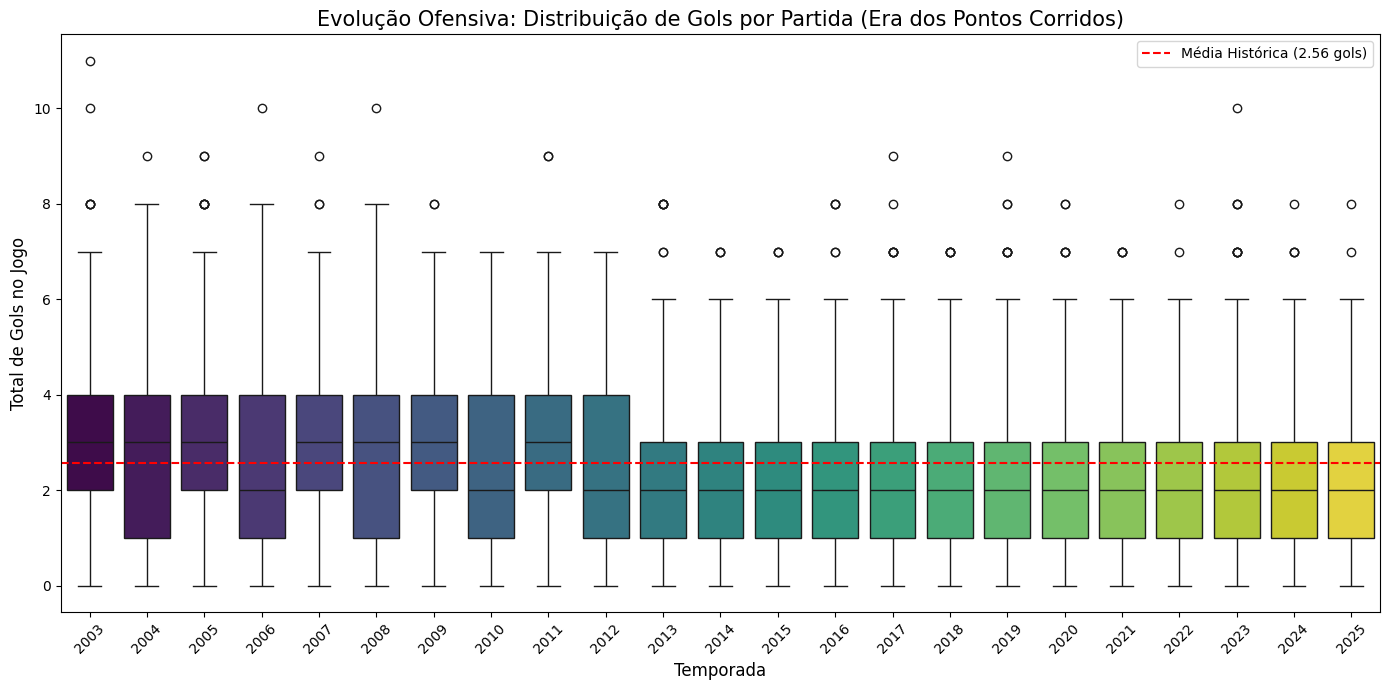

In [ ]:
df_partidas['total_gols'] = df_partidas['home_team_score'] + df_partidas['away_team_score']
if 'ano' not in df_partidas.columns:
  df_partidas['ano'] = pd.to_datetime(df_partidas['date']).dt.year

plt.figure(figsize=(14, 7))
sns.boxplot(
    data=df_partidas,
    x='ano',
    y='total_gols',
    hue='ano',
    palette='viridis',
    legend=False
)

media_historica = df_partidas['total_gols'].mean()
plt.axhline(media_historica, color='red', linestyle='--', label=f'Média Histórica ({media_historica:.2f} gols)')

plt.title('Evolução Ofensiva: Distribuição de Gols por Partida (Era dos Pontos Corridos)', fontsize=15)
plt.xlabel('Temporada', fontsize=12)
plt.ylabel('Total de Gols no Jogo', fontsize=12)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig('02_boxplot_gols_por_ano.png', dpi=150, bbox_inches='tight')
plt.show()

📊 Gráfico 2: Consistentes x Ioiôs

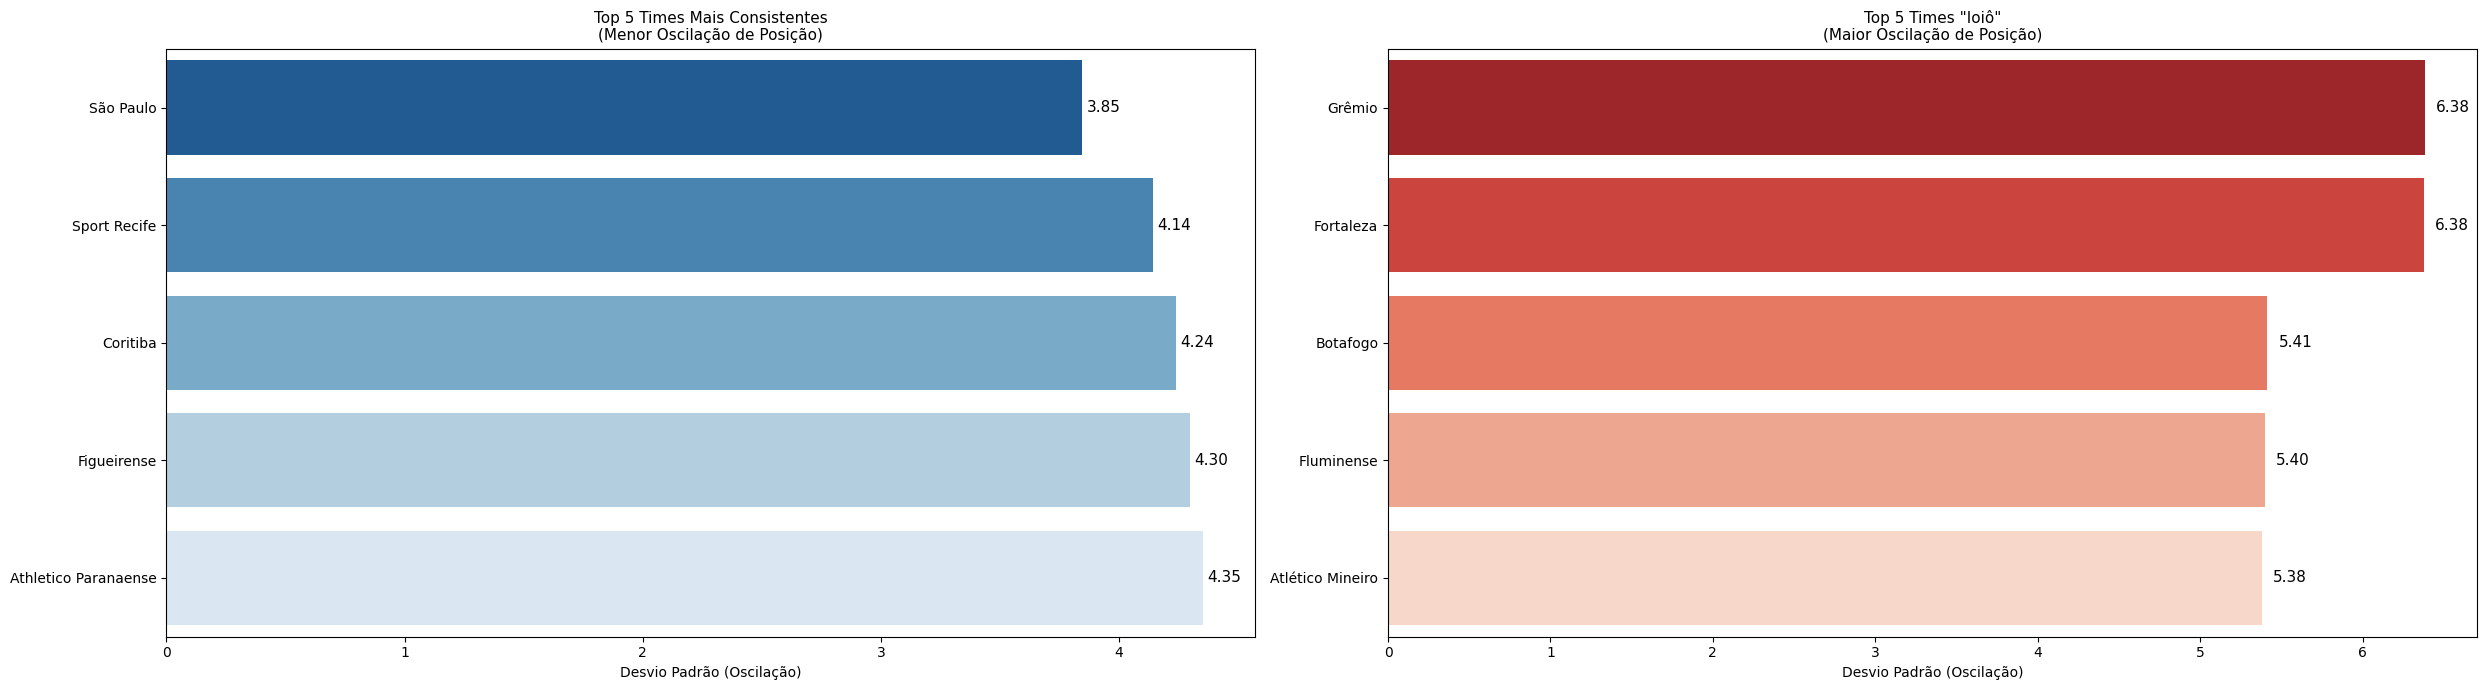

In [ ]:
df_consistencia_valida = df_consistencia[df_consistencia['Participações'] >= 10]
consistentes = df_consistencia_valida.sort_values(by='Desvio_padrão', ascending=True).head(5)
ioios = df_consistencia_valida.sort_values(by='Desvio_padrão', ascending=False).head(5)

fig, axes = plt.subplots(1, 2, figsize=(25, 7))

sns.barplot(
    data=consistentes,
    x='Desvio_padrão',
    y='Time',
    hue='Time',
    ax=axes[0],
    palette='Blues_r',
    legend=False
    )
axes[0].set_title('Top 5 Times Mais Consistentes\n(Menor Oscilação de Posição)', fontsize=11)
axes[0].set_xlabel('Desvio Padrão (Oscilação)')
axes[0].set_ylabel('')

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f', padding=3, fontsize=11)

sns.barplot(
    data=ioios,
    x='Desvio_padrão',
    y='Time',
    hue='Time',
    ax=axes[1],
    palette='Reds_r',
    legend=False
    )
axes[1].set_title('Top 5 Times "Ioiô"\n(Maior Oscilação de Posição)', fontsize=11)
axes[1].set_xlabel('Desvio Padrão (Oscilação)')
axes[1].set_ylabel('')

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.2f', padding=8, fontsize=11)

plt.tight_layout()
plt.savefig('02_consistentes_x_ioios.png', dpi=150, bbox_inches='tight')
plt.show()